# Normalized Time Comparison

Load one policy result store twice: once with raw simulator steps and once with activation-opportunities-per-agent time.


In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tasks.policies import load_policy_results

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "tasks").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Edit this path to compare another run.
ZARR_PATH = PROJECT_ROOT / "artifacts/simulation_runs/run-20260513T155848.zarr"
ZARR_PATH

PosixPath('/home/hdahmou/Network_creation/artifacts/simulation_runs/run-20260513T155848.zarr')

In [ ]:
raw = load_policy_results(ZARR_PATH)
normalized = load_policy_results(ZARR_PATH, normalize_time=True)

print("raw sizes:", dict(raw.sizes))
print("normalized sizes:", dict(normalized.sizes))
print("normalized attrs:")
for key in (
    "normalize_time",
    "time_axis",
    "raw_step_labels",
    "common_normalized_time_max",
):
    value = normalized.attrs.get(key)
    if key == "raw_step_labels" and isinstance(value, list):
        value = value[:5] + (["..."] if len(value) > 5 else [])
    print(f"  {key}: {value}")

raw sizes: {'n_agents': 5, 'best_response_proportion': 1, 'parameter_row': 8192, 'theta_parameter': 6, 'step': 601, 'observable': 3}
normalized sizes: {'n_agents': 5, 'best_response_proportion': 1, 'parameter_row': 8192, 'theta_parameter': 6, 'step': 121, 'observable': 3}
normalized attrs:
  normalize_time: True
  time_axis: activation_opportunities_per_agent
  raw_step_labels: [0.0, 5.0, 10.0, 15.0, 20.0, '...']
  common_normalized_time_max: 60.0


In [ ]:
config_path = Path(raw.attrs["config_path"])
config = json.loads(config_path.read_text())
n_actors = int(config["simulator"]["actor_scheduler"]["n_actors"])
raw_steps = np.asarray(raw.coords["step"].values, dtype=float)

rows = []
for n_agents in raw.coords["n_agents"].values:
    n_agents = int(n_agents)
    effective_n_actors = min(n_actors, n_agents)
    rows.append(
        pd.DataFrame(
            {
                "n_agents": n_agents,
                "raw_step": raw_steps,
                "activation_opportunities_per_agent": raw_steps
                * effective_n_actors
                / n_agents,
            }
        )
    )

time_table = pd.concat(rows, ignore_index=True)
display(
    time_table.pivot(
        index="raw_step",
        columns="n_agents",
        values="activation_opportunities_per_agent",
    ).head(12)
)
print("returned normalized step coordinate:")
print(np.asarray(normalized.coords["step"].values[:12]))

n_agents,10,20,30,40,50
raw_step,,,,,
0.0,0.0,0.00,0.000000,0.000,0.0
5.0,0.5,0.25,0.166667,0.125,0.1
10.0,1.0,0.50,0.333333,0.250,0.2
15.0,1.5,0.75,0.500000,0.375,0.3
20.0,2.0,1.00,0.666667,0.500,0.4
25.0,2.5,1.25,0.833333,0.625,0.5
30.0,3.0,1.50,1.000000,0.750,0.6
35.0,3.5,1.75,1.166667,0.875,0.7
40.0,4.0,2.00,1.333333,1.000,0.8


returned normalized step coordinate:
[0.  0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5 5.  5.5]


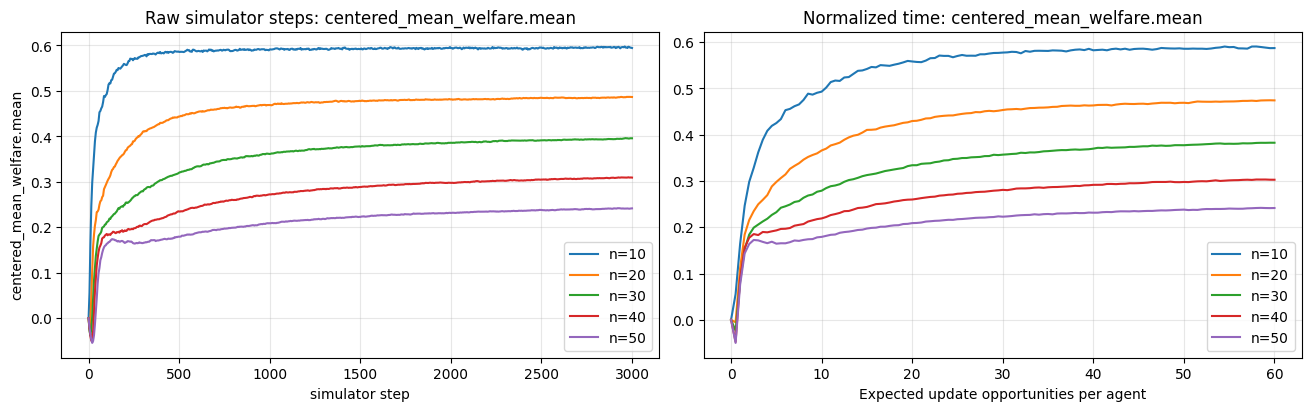

In [ ]:
preferred_observable = "centered_mean_welfare.mean"
observable_names = [str(value) for value in raw.coords["observable"].values]
observable = (
    preferred_observable
    if preferred_observable in observable_names
    else observable_names[0]
)


def mean_series(ds, n_agents):
    series = ds["x"].sel(n_agents=n_agents, observable=observable)
    reduce_dims = [dim for dim in series.dims if dim != "step"]
    return series.mean(dim=reduce_dims, skipna=True)


fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
for n_agents in raw.coords["n_agents"].values:
    axes[0].plot(
        raw.coords["step"].values,
        mean_series(raw, n_agents).values,
        label=f"n={int(n_agents)}",
    )
    axes[1].plot(
        normalized.coords["step"].values,
        mean_series(normalized, n_agents).values,
        label=f"n={int(n_agents)}",
    )

axes[0].set_title(f"Raw simulator steps: {observable}")
axes[0].set_xlabel("simulator step")
axes[0].set_ylabel(observable)
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title(f"Normalized time: {observable}")
axes[1].set_xlabel("Expected update opportunities per agent")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.show()

,raw_last_step,normalized_common_horizon
n_agents,,
10,0.594508,0.587314
20,0.486655,0.474285
30,0.395856,0.382710
40,0.309430,0.302763
50,0.241641,0.241640


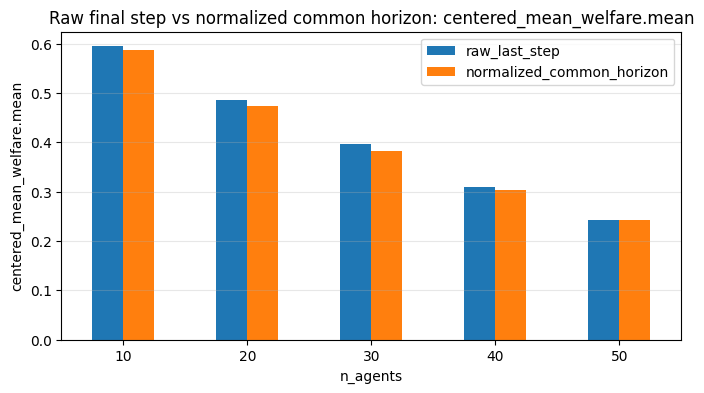

In [ ]:
final_rows = []
for n_agents in raw.coords["n_agents"].values:
    final_rows.append(
        {
            "n_agents": int(n_agents),
            "raw_last_step": float(mean_series(raw, n_agents).isel(step=-1).values),
            "normalized_common_horizon": float(
                mean_series(normalized, n_agents).isel(step=-1).values
            ),
        }
    )

final_values = pd.DataFrame(final_rows).set_index("n_agents")
display(final_values)

ax = final_values.plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_title(f"Raw final step vs normalized common horizon: {observable}")
ax.set_ylabel(observable)
ax.grid(axis="y", alpha=0.3)
plt.show()